# [8조] 이미지 기반 머신러닝을 활용한 선박 종류 분류 모델 개발

## 1. 환경 설정 및 데이터 수집 (Environment & Data Setup)

* 라이브러리(Numpy, Matplotlib, Scikit-learn)를 불러옵니다.
* 수정, 검증에 편의를 위한 중앙 관리 변수를 지정합니다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns

# 데이터 폴더 경로 및 카테고리 설정
categories = ['container', 'passenger', 'tanker']
base_dir = '/content/drive/MyDrive/Colab Notebooks/dataset'

RANDOM_SEED = 123123
TEST_SIZE = 0.2
IMG_SIZE = 64

## 2. 데이터 전처리 (Data Preprocessing)
* 4단계 전처리를(Resize, Grayscale, Flatten, Normalization)를 수행합니다.
* 3주차에 실습한 리스트(List)와 6주차 함수(def), 반복문(for), 흐름 제어문(continue) 등 파이썬 기초 문법을 종합적으로 활용하여 모듈화하였습니다.

In [19]:
def preprocess_images_advanced(base_dir, categories, img_size=64, use_color=False):
    X_list = []
    y_list = []

    for category in categories:
        label = categories.index(category)
        folder_path = f"{base_dir}/{category}"

        for file in sorted(os.listdir(folder_path)):
            img_path = f"{folder_path}/{file}"
            img = cv2.imread(img_path)

            if img is None:
                continue

            # 1. Resize
            img_resized = cv2.resize(img, (img_size, img_size))

            # 2 & 3. Color Conversion 및 Flatten
            if use_color:
                # RGB 모드: 색상 정보가 중요할 때
                img_color = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
                img_flatten = img_color.flatten()
            else:
                # Grayscale 모드: 전체적인 윤곽과 형태만 볼 때
                img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
                img_flatten = img_gray.flatten()

            X_list.append(img_flatten)
            y_list.append(label)

    # 리스트를 Numpy 배열로 변환
    X_raw = np.array(X_list)
    y = np.array(y_list)

    # 4. Normalization - MinMaxScaler 적용
    # 실제 데이터의 최소/최대값을 기준으로 0~1 사이로 정밀하게 압축합니다.
    scaler = MinMaxScaler()
    X_normalized = scaler.fit_transform(X_raw)

    return X_normalized, y

# ==========================================
# [실험 1] 흑백(Grayscale) 이미지로 전처리
print("전처리 1: 흑백(Grayscale) 이미지 변환 중...")
X_gray, y = preprocess_images_advanced(base_dir, categories, img_size=IMG_SIZE, use_color=False)
print("흑백 데이터 형태:", X_gray.shape)

# [실험 2] 컬러(RGB) 이미지로 전처리
print("\n전처리 2: 컬러(RGB) 이미지 변환 중...")
X_color, y = preprocess_images_advanced(base_dir, categories, img_size=IMG_SIZE, use_color=True)
print("컬러 데이터 형태:", X_color.shape)

전처리 1: 흑백(Grayscale) 이미지 변환 중...
흑백 데이터 형태: (280, 4096)

전처리 2: 컬러(RGB) 이미지 변환 중...
컬러 데이터 형태: (280, 12288)


## 3. 최적의 모델 및 전처리 조합 탐색 (Model & Preprocessing Selection)

* **목표**

4가지 분류 모델과 2가지 전처리 방식(Grayscale vs RGB)의 모든 조합을 테스트하여, 선박 이미지 분류에 가장 뛰어난 성능을 내는 메인 모델을 선정합니다.

* **실험 설계**

(1) 4개의 모델(Random Forest, SVM, KNN, Logistic Regression)을 준비합니다.

(2) `train_test_split()`를 활용하여 흑백(4,096차원)과 컬러(12,288차원) 데이터를 각각 학습용(Train)과 테스트용(Test)으로 분할하여 모델의 과적합을 방지합니다.

(3) `accuracy_score`를 기준으로 테스트 데이터 예측 결과가 가장 높은 '모델 + 전처리' 조합을 최종 메인 모델로 선정합니다.

In [20]:
# 데이터를 흑백/컬러 세트로 정리
data_sets = {
    "Grayscale (4096차원)": (X_gray, y),
    "RGB Color (12288차원)": (X_color, y)
}

results = []

print("[전처리 및 모델 조합 테스트 시작]")
print("-" * 60)

for data_name, (data_X, data_y) in data_sets.items():
    # 데이터 분할 (중앙 관리 변수 TEST_SIZE, RANDOM_SEED 적용)
    X_train, X_test, y_train, y_test = train_test_split(
        data_X, data_y, test_size=TEST_SIZE, random_state=RANDOM_SEED
    )

    print(f"\n데이터 타입: {data_name}")

    # 4가지 모델 정의 (중앙 관리 변수 RANDOM_SEED 적용) - 매 반복마다 완전히 새로운 모델 객체 생성
    model_list = {
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED),
        "SVM": SVC(kernel='rbf', C=10, random_state=RANDOM_SEED),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
    }

    for model_name, model in model_list.items():
        # 모델 학습
        model.fit(X_train, y_train)
        # 결과 예측
        y_pred = model.predict(X_test)
        # 정확도 측정
        acc = accuracy_score(y_test, y_pred)

        # 4번 가시화 단계를 위해 결과 저장
        results.append((data_name, model_name, acc, model, X_test, y_test, y_pred))
        print(f"   > {model_name:20s} 정확도: {acc * 100:.2f}%")

print("\n" + "=" * 60)
# 가장 성적이 좋은 조합 찾기
best_res = max(results, key=lambda x: x[2])

# 최종 변수 할당
best_data_name, best_model_name, best_acc, best_model, best_X_test, best_y_test, best_y_pred = best_res

print(f"최종 선정 조합: [{best_data_name}] + [{best_model_name}]")
print(f"최고 정확도: {best_acc * 100:.2f}%")
print("=" * 60)

[전처리 및 모델 조합 테스트 시작]
------------------------------------------------------------

데이터 타입: Grayscale (4096차원)
   > Random Forest        정확도: 53.57%
   > SVM                  정확도: 58.93%
   > KNN                  정확도: 30.36%
   > Logistic Regression  정확도: 55.36%

데이터 타입: RGB Color (12288차원)
   > Random Forest        정확도: 53.57%
   > SVM                  정확도: 64.29%
   > KNN                  정확도: 51.79%
   > Logistic Regression  정확도: 55.36%

최종 선정 조합: [RGB Color (12288차원)] + [SVM]
최고 정확도: 64.29%


## 4. 예측 결과 평가 및 가시화 (Model Evaluation & Visualization)

* **분석 목표:**

3번 단계에서 최종 선정된 최적의 모델과 테스트 데이터를 그대로 활용하여, 모델의 객관적인 성능을 평가하고 오답 패턴을 시각적으로 분석합니다.

* **진행 순서 및 적용 내용**

(1) **오차 행렬(Confusion Matrix) 분석:** `confusion_matrix`를 사용하여 모델이 어떤 선박(Container, Passenger, Tanker)을 주로 혼동하는지 세부적인 오답 패턴을 분석합니다. 시각적 가독성을 높이기 위해 `seaborn` 라이브러리의 히트맵을 활용합니다.

(2) **정답/오답 사례 시각화:** 실제 예측 사진들을 나열합니다. 모델 학습을 위해 1차원(Flatten)으로 변환했던 데이터를 본래의 2차원(흑백) 또는 3차원(컬러) 배열로 복원(`reshape`)한 뒤, `Matplotlib`의 `imshow()`와 `axis('off')` 함수를 활용하여 직관적으로 가시화합니다.

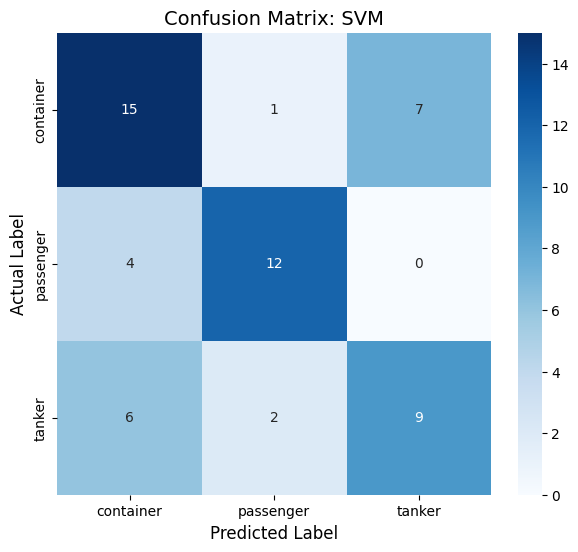


[상세 성능 평가 보고서]
              precision    recall  f1-score   support

   container       0.60      0.65      0.62        23
   passenger       0.80      0.75      0.77        16
      tanker       0.56      0.53      0.55        17

    accuracy                           0.64        56
   macro avg       0.65      0.64      0.65        56
weighted avg       0.65      0.64      0.64        56



In [21]:
# 오차 행렬 계산
cm = confusion_matrix(best_y_test, best_y_pred)

# 시각화 (seaborn 활용)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=categories, yticklabels=categories)

plt.title(f"Confusion Matrix: {best_model_name}", fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.show()

# 추가 성능 지표
print("\n[상세 성능 평가 보고서]")
print(classification_report(best_y_test, best_y_pred, target_names=categories))

이미지 가시화 결과 (데이터 타입: RGB Color (12288차원))


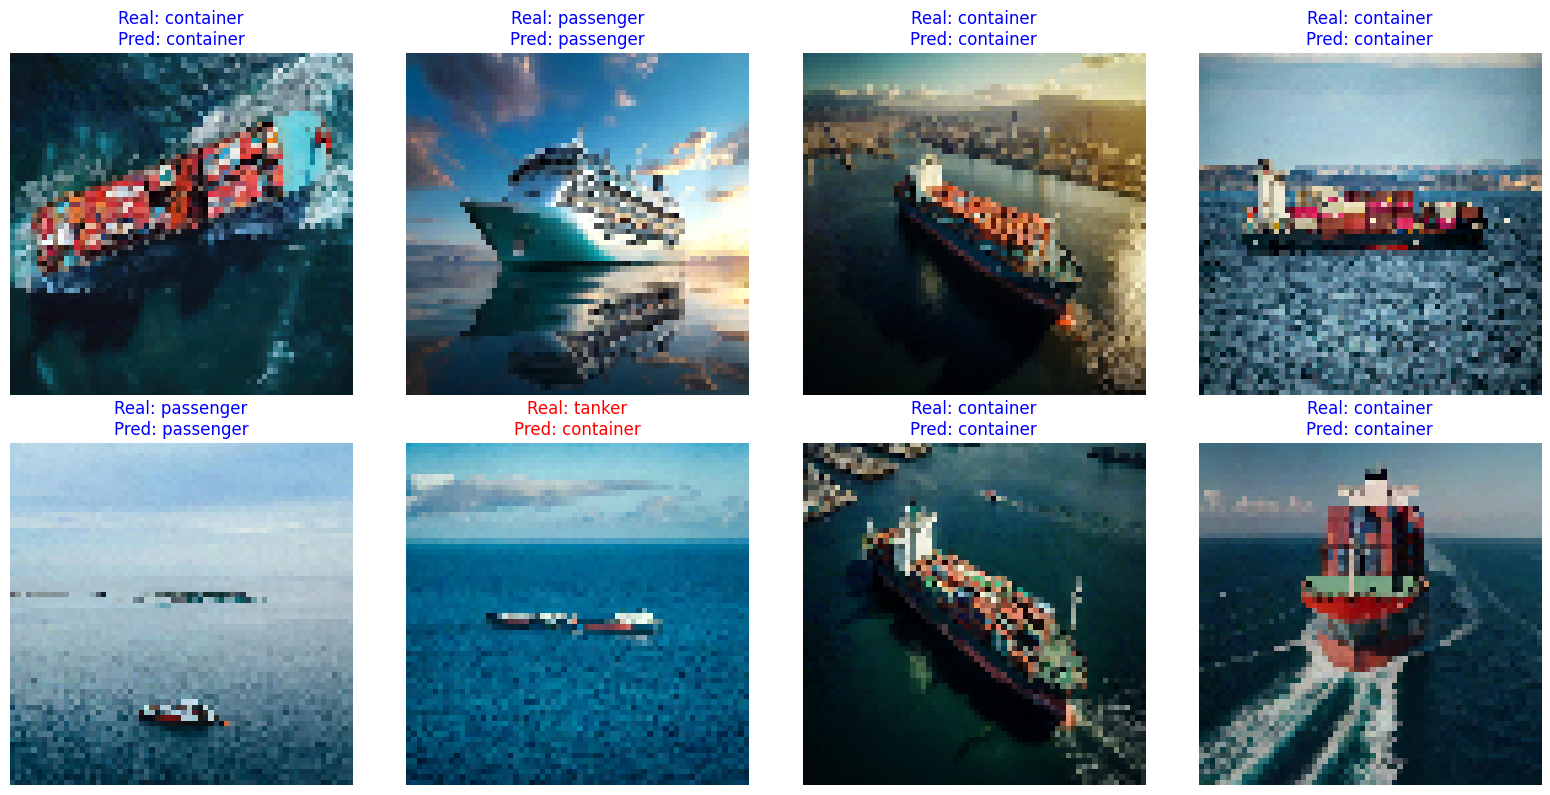

In [22]:
print(f"이미지 가시화 결과 (데이터 타입: {best_data_name})")

plt.figure(figsize=(16, 8))
img_size = 64
is_color = (best_X_test.shape[1] > IMG_SIZE * IMG_SIZE)

# 테스트 데이터 중 앞의 8개 샘플 확인
for i in range(8):
    plt.subplot(2, 4, i + 1)

    # 데이터 복구 및 Clipping (0~1 범위 강제 고정으로 경고 방지)
    if is_color:
        img_visual = best_X_test[i].reshape(IMG_SIZE, IMG_SIZE, 3)
    else:
        img_visual = best_X_test[i].reshape(IMG_SIZE, IMG_SIZE)

    img_visual = np.clip(img_visual, 0, 1)

    plt.imshow(img_visual, cmap='gray' if not is_color else None)
    plt.axis('off') # 불필요한 축 제거

    real_nm = categories[best_y_test[i]]
    pred_nm = categories[best_y_pred[i]]

    # 정답/오답 색상 구분
    color = 'blue' if real_nm == pred_nm else 'red'
    plt.title(f"Real: {real_nm}\nPred: {pred_nm}", color=color, fontsize=12)

plt.tight_layout()
plt.show()